# Lab 9: Sequence-to-Sequence Models in Python

## Step 1: Import libraries

In [1]:
import random
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

I0000 00:00:1791622976.538262   11695 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791622976.539099   11695 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791622978.902035   11695 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791622978.902698   11695 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Step 2: Create the dataset

In [2]:
formats = ['%d %B %Y', '%d %b %Y', '%B %d, %Y', '%d/%m/%Y', '%d.%m.%y', '%A, %d %B %Y', '%b %d %Y', '%d-%b-%y']

def random_date():
    d = datetime.date(1990, 1, 1) + datetime.timedelta(days=random.randint(0, 14600))
    return d.strftime(random.choice(formats)).lower(), d.isoformat()

data = [random_date() for _ in range(20000)]
df = pd.DataFrame(data, columns=['invoice_date', 'standard_date'])
print(df.head(8))
print(df['invoice_date'].str.len().describe())

   invoice_date standard_date
0   07 sep 2018    2018-09-07
1      14.02.91    1991-02-14
2    26/12/2000    2000-12-26
3   05 apr 1996    1996-04-05
4   10 may 2020    2020-05-10
5   jun 27 2016    2016-06-27
6  05 june 1991    1991-06-05
7    16/03/1994    1994-03-16
count    20000.000000
mean        12.657900
std          4.692182
min          8.000000
25%         10.000000
50%         11.000000
75%         15.000000
max         28.000000
Name: invoice_date, dtype: float64


## Step 3: Prepare the inputs

In [3]:
in_chars = sorted(set(''.join(df['invoice_date'])))
out_chars = sorted(set(''.join(df['standard_date'])))
in_index = {c: i + 1 for i, c in enumerate(in_chars)}
out_index = {c: i + 1 for i, c in enumerate(out_chars)}
inv_out = {i: c for c, i in out_index.items()}
start_id = len(out_chars) + 1
in_vocab = len(in_chars) + 1
out_vocab = len(out_chars) + 2
print('Input vocabulary :', in_vocab)
print('Output vocabulary:', out_vocab)

max_in = 30
X = pad_sequences([[in_index[c] for c in s] for s in df['invoice_date']], maxlen=max_in, padding='post')
y = np.array([[out_index[c] for c in s] for s in df['standard_date']])
y_in = np.concatenate([np.full((len(y), 1), start_id), y[:, :-1]], axis=1)

X_train, X_test = X[:16000], X[16000:]
y_train, y_test = y[:16000], y[16000:]
y_in_train, y_in_test = y_in[:16000], y_in[16000:]
print(X_train.shape, y_in_train.shape, y_train.shape)
print(y[0])
print(y_in[0])

Input vocabulary : 38
Output vocabulary: 13
(16000, 30) (16000, 10) (16000, 10)
[ 4  2  3 10  1  2 11  1  2  9]
[12  4  2  3 10  1  2 11  1  2]


## Step 4: Build the encoder and decoder

In [4]:
def build_seq2seq(units):
    enc_input = Input(shape=(max_in,), name='encoder_input')
    enc_emb = Embedding(in_vocab, 32, mask_zero=True)(enc_input)
    _, state_h, state_c = LSTM(units, return_state=True, name='encoder_lstm')(enc_emb)
    dec_input = Input(shape=(None,), name='decoder_input')
    dec_emb = Embedding(out_vocab, 32)(dec_input)
    dec_seq, _, _ = LSTM(units, return_sequences=True, return_state=True, name='decoder_lstm')(dec_emb, initial_state=[state_h, state_c])
    output = Dense(out_vocab, activation='softmax', name='output')(dec_seq)
    model = Model([enc_input, dec_input], output)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

seq2seq = build_seq2seq(64)
seq2seq.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 30, 32)    │      1,216 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 30)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 32)  │        416 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 64),      │     24,832 │ embedding[0][0],  │
│                     │ (None, 64),       │            │ not_equal[0][0]   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │     24,832 │ embedding_1[0][0… │
│                     │ 64), (None, 64),  │            │ encoder_lstm[0][… │
│                     │ (None, 64)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None, 13)  │        845 │ decoder_lstm[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 52,141 (203.68 KB)

 Trainable params: 52,141 (203.68 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Train the model

Epoch 1/15


113/113 - 11s - 94ms/step - accuracy: 0.4866 - loss: 1.5771 - val_accuracy: 0.6212 - val_loss: 1.0270


Epoch 2/15


113/113 - 5s - 46ms/step - accuracy: 0.6586 - loss: 0.9067 - val_accuracy: 0.7176 - val_loss: 0.7862


Epoch 3/15


...

113/113 - 5s - 45ms/step - accuracy: 0.9949 - loss: 0.0345 - val_accuracy: 0.9953 - val_loss: 0.0304


Epoch 14/15


113/113 - 5s - 43ms/step - accuracy: 0.9967 - loss: 0.0267 - val_accuracy: 0.9957 - val_loss: 0.0268


Epoch 15/15


113/113 - 5s - 46ms/step - accuracy: 0.9979 - loss: 0.0214 - val_accuracy: 0.9967 - val_loss: 0.0238


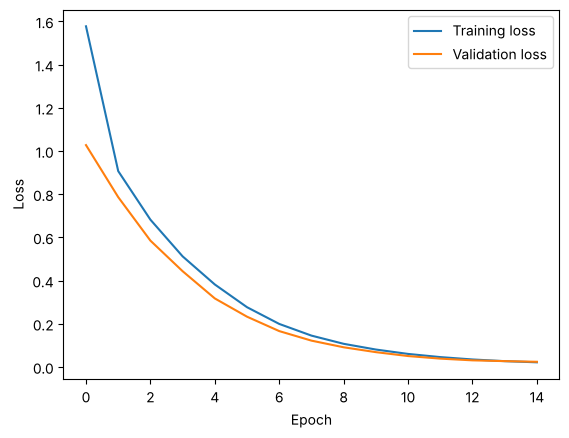

In [5]:
history = seq2seq.fit(
    [X_train, y_in_train], y_train,
    epochs=15, batch_size=128,
    validation_split=0.1, verbose=2
)

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## Step 6: Generate and evaluate the output

In [6]:
def translate(model, X):
    dec = np.full((len(X), 1), start_id)
    for _ in range(10):
        probs = model([X, dec], training=False).numpy()
        next_id = probs[:, -1, :].argmax(axis=-1)
        dec = np.concatenate([dec, next_id[:, None]], axis=1)
    return dec[:, 1:]

def to_text(ids):
    return ''.join(inv_out.get(i, '?') for i in ids)

pred = translate(seq2seq, X_test)
print('Exact-match accuracy:', round(np.mean(np.all(pred == y_test, axis=1)), 4))
print('Character accuracy  :', round(np.mean(pred == y_test), 4))

test_df = df.iloc[16000:].copy()
test_df['predicted'] = [to_text(p) for p in pred]
test_df['correct'] = test_df['predicted'] == test_df['standard_date']
print(test_df.sample(8, random_state=1))
print(test_df[~test_df['correct']].head(10))

Exact-match accuracy: 0.963
Character accuracy  : 0.9926
            invoice_date standard_date   predicted  correct
16200          23-sep-14    2014-09-23  2014-09-23     True
17078     april 06, 1992    1992-04-06  1992-04-06     True
16610           08.07.04    2004-07-08  2004-07-08     True
18159     march 21, 2022    2022-03-21  2022-03-21     True
17169  21 september 2005    2005-09-21  2005-09-21     True
18448        16 jul 2012    2012-07-16  2012-07-16     True
18938          15-oct-02    2002-10-15  2002-10-15     True
16813       14 july 2026    2026-07-14  2026-07-14     True
          invoice_date standard_date   predicted  correct
16017         11.11.00    2000-11-11  2001-10-11    False
16071       09/07/2020    2020-07-09  2020-09-07    False
16098      sep 06 1993    1993-09-06  1993-06-09    False
16111       01/09/2005    2005-09-01  2005-01-09    False
16153  10 january 2000    2000-01-10  2000-01-11    False
16225         02.01.28    2028-01-02  2028-10-02    Fal

## Step 7: See the bottleneck

In [7]:
print('Context vector shape:', seq2seq.get_layer('encoder_lstm').output[1].shape)

small = build_seq2seq(16)
small.fit([X_train, y_in_train], y_train, epochs=15, batch_size=128, validation_split=0.1, verbose=0)
small_pred = translate(small, X_test)
print('Exact-match accuracy with 16 units:', round(np.mean(np.all(small_pred == y_test, axis=1)), 4))

Context vector shape: (None, 64)


Exact-match accuracy with 16 units: 0.2648


## Lab 9 Task 1: Own invoice dates

In [8]:
my_dates = ['15 august 2021', 'mar 03 2015', '25/12/1999', '2018/09/07', '7th sep 2018']
my_true = ['2021-08-15', '2015-03-03', '1999-12-25', '2018-09-07', '2018-09-07']
my_X = pad_sequences([[in_index.get(c, 0) for c in s] for s in my_dates], maxlen=max_in, padding='post')
my_pred = [to_text(p) for p in translate(seq2seq, my_X)]
task1_df = pd.DataFrame({'Invoice date': my_dates, 'Expected': my_true, 'Predicted': my_pred})
task1_df['Correct'] = task1_df['Expected'] == task1_df['Predicted']
task1_df['Format seen in training'] = [True, True, True, False, False]
print(task1_df)

     Invoice date    Expected   Predicted  Correct  Format seen in training
0  15 august 2021  2021-08-15  2021-08-15     True                     True
1     mar 03 2015  2015-03-03  2015-03-03     True                     True
2      25/12/1999  1999-12-25  1999-12-25     True                     True
3      2018/09/07  2018-09-07  2007-06-08    False                    False
4    7th sep 2018  2018-09-07  2018-07-19    False                    False


The model got the three dates in trained formats right and both dates in unseen formats wrong: '2018/09/07' became 2007-06-08 and '7th sep 2018' became 2018-07-19. In '2018/09/07' the year comes first and is separated by '/', which in training always meant day/month/year, so the model reads the digits in the wrong positions. In '7th sep 2018' the day has one digit and is followed by 'th', which never appeared in training. The model has no rule for these positions, so it places digits in the wrong part of the output. A seq2seq model only generalises to patterns similar to its training data.

## Lab 9 Task 2: Effect of the number of units

   Units  Context vector size  Parameters  Exact-match accuracy  \
0      8                   16        4373                0.0095   
1     16                   32        8125                0.3068   
2     32                   64       18701                0.8265   
3     64                  128       52141                0.9795   
4    128                  256      168173                1.0000   

   Character accuracy  
0              0.6647  
1              0.8452  
2              0.9613  
3              0.9958  
4              1.0000  


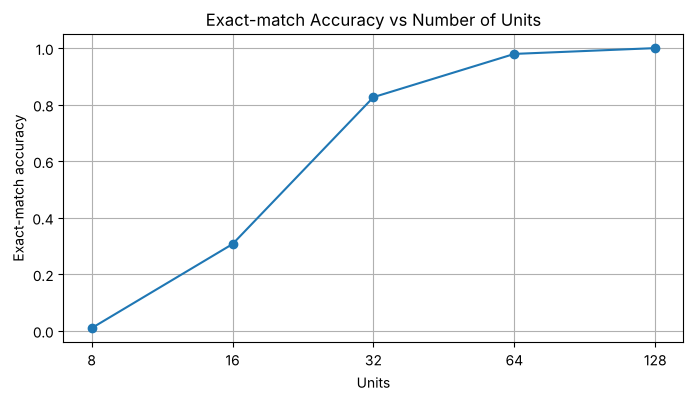

In [9]:
unit_results = []
for u in [8, 16, 32, 64, 128]:
    m = build_seq2seq(u)
    m.fit([X_train, y_in_train], y_train, epochs=15, batch_size=128, validation_split=0.1, verbose=0)
    p = translate(m, X_test)
    unit_results.append({
        'Units': u,
        'Context vector size': 2 * u,
        'Parameters': m.count_params(),
        'Exact-match accuracy': round(float(np.mean(np.all(p == y_test, axis=1))), 4),
        'Character accuracy': round(float(np.mean(p == y_test)), 4)
    })
units_df = pd.DataFrame(unit_results)
print(units_df)

plt.figure(figsize=(8, 4))
plt.plot(units_df['Units'], units_df['Exact-match accuracy'], marker='o')
plt.xscale('log', base=2)
plt.xticks(units_df['Units'], units_df['Units'])
plt.title('Exact-match Accuracy vs Number of Units')
plt.xlabel('Units')
plt.ylabel('Exact-match accuracy')
plt.grid(True)
plt.show()

The encoder passes the whole input to the decoder only through state_h and state_c, so the context vector has 2 x units numbers. With 8 units (16 numbers) the vector is far too small and exact-match accuracy is only 0.0095; with 16 units it is 0.3068. Accuracy rises sharply to 0.8265 at 32 units and 0.9795 at 64 units, and then levels off, reaching 1.0 at 128 units, while the parameter count keeps growing roughly with the square of the units (52,141 at 64 units and 168,173 at 128). Beyond 64 units extra capacity gives little gain, which shows that the size of the fixed context vector is the main limit of the plain seq2seq model.

## Lab 9 Task 3: Accuracy by input length and format

In [10]:
def find_format(s):
    for f in formats:
        try:
            datetime.datetime.strptime(s, f)
            return f
        except ValueError:
            pass
    return 'unknown'

def error_type(row):
    p, t = row['predicted'], row['standard_date']
    if p == t:
        return 'correct'
    if p[:4] == t[:4] and p[5:7] == t[8:10] and p[8:10] == t[5:7]:
        return 'day-month swap'
    parts = [name for name, a, b in [('year', p[:4], t[:4]), ('month', p[5:7], t[5:7]), ('day', p[8:10], t[8:10])] if a != b]
    return ' + '.join(parts) + ' wrong' if parts else 'separator wrong'

test_df['length'] = test_df['invoice_date'].str.len()
test_df['length_group'] = pd.cut(test_df['length'], bins=[0, 9, 12, 16, 20, 30], labels=['8-9', '10-12', '13-16', '17-20', '21-28'])
test_df['format'] = test_df['invoice_date'].apply(find_format)
test_df['error_type'] = test_df.apply(error_type, axis=1)

by_length = test_df.groupby('length_group', observed=True)['correct'].agg(['count', 'mean']).rename(columns={'count': 'Samples', 'mean': 'Exact-match accuracy'})
print(by_length.round(4))

by_format = test_df.groupby('format')['correct'].agg(['count', 'mean']).rename(columns={'count': 'Samples', 'mean': 'Exact-match accuracy'}).sort_values('Exact-match accuracy')
print(by_format.round(4))

errors = test_df[~test_df['correct']]
print(errors['error_type'].value_counts())
print(errors.groupby('format')['error_type'].agg(lambda s: s.value_counts().index[0]))

              Samples  Exact-match accuracy
length_group                               
8-9              1007                0.9563
10-12            1688                0.9585
13-16             599                0.9649
17-20             261                0.9808
21-28             445                0.9820
              Samples  Exact-match accuracy
format                                     
%d/%m/%Y          512                0.9258
%d.%m.%y          503                0.9364
%b %d %Y          518                0.9556
%B %d, %Y         466                0.9571
%d-%b-%y          504                0.9762
%A, %d %B %Y      511                0.9824
%d %B %Y          556                0.9838
%d %b %Y          430                0.9884
error_type
day wrong             57
month + day wrong     52
month wrong           29
day-month swap         8
year + month wrong     1
year + day wrong       1
Name: count, dtype: int64
format
%A, %d %B %Y            day wrong
%B %d, %Y               

The numeric formats cause the most errors: '%d/%m/%Y' (0.9258) and '%d.%m.%y' (0.9364) are the two least accurate, because the day and the month are both two digits and only their position separates them. The most common error type is a wrong day (57 errors), followed by month and day both wrong (52) and month wrong (29); clean day-month swaps are rare (8). So the model usually knows which digits appear but puts some of them in the wrong place. Formats with a month name are easier, because the month is identified by letters that cannot be confused with the day. Longer inputs are not harder here: the 21-28 character group (long month and weekday names) is the most accurate (0.982) and the short 8-9 character group, which is mostly numeric dates, is the least accurate (0.9563).

## Lab 9 Task 4: Business estimate

In [11]:
best_acc = max(units_df['Exact-match accuracy'].max(), float(np.mean(np.all(pred == y_test, axis=1))))
monthly_invoices = 10000
wrong_per_month = round(monthly_invoices * (1 - best_acc))
print('Best exact-match accuracy :', round(best_acc, 4))
print('Expected wrong dates/month:', wrong_per_month, 'out of', monthly_invoices)

Best exact-match accuracy : 1.0
Expected wrong dates/month: 0 out of 10000


The best model (128 units) got all 4,000 test dates right, so the estimate is 0 wrong dates per month out of 10,000. This figure is too optimistic for real use: the test data contains only the same 8 formats used in training, and Task 1 showed that the model fails on formats it has not seen, such as '2018/09/07' and '7th sep 2018'. A wrong date can cause late payments, wrong due dates and errors in period-end reporting, so full automation is still not safe. The recommended approach is to use the model with human review: dates that fail a validity check, are numeric with a day value of 12 or less (where day and month could be swapped), or come in a new supplier format should go to an accounts-payable clerk. This removes most of the manual work while keeping control over the risky cases.

## Lab Assignment 3: Amounts in words to digits

### Task 1: Task description and example pairs

In [12]:
random.seed(3)
np.random.seed(3)
tf.random.set_seed(3)

ones = ['zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight', 'nine', 'ten',
        'eleven', 'twelve', 'thirteen', 'fourteen', 'fifteen', 'sixteen', 'seventeen', 'eighteen', 'nineteen']
tens = ['', '', 'twenty', 'thirty', 'forty', 'fifty', 'sixty', 'seventy', 'eighty', 'ninety']

def below_thousand(n, use_and):
    parts = []
    if n >= 100:
        parts += [ones[n // 100], 'hundred']
        n %= 100
        if n and use_and:
            parts.append('and')
    if n >= 20:
        parts.append(tens[n // 10])
        n %= 10
        if n:
            parts.append(ones[n])
    elif n > 0:
        parts.append(ones[n])
    return parts

def number_to_words(n):
    use_and = random.random() < 0.3
    parts = []
    if n >= 1000:
        parts += below_thousand(n // 1000, use_and) + ['thousand']
        n %= 1000
    if n:
        parts += below_thousand(n, use_and)
    return ' '.join(parts)

numbers = random.sample(range(1, 10000), 3000) + random.sample(range(10000, 1000000), 9000)
random.shuffle(numbers)
amount_df = pd.DataFrame({'amount_words': [number_to_words(n) for n in numbers], 'amount_digits': [str(n) for n in numbers]})
print(amount_df.head(10).to_string())
print(len(amount_df), 'pairs')
print(amount_df['amount_words'].str.len().describe())

                                                           amount_words amount_digits
0                                twenty six thousand seven hundred four         26704
1                nine hundred sixty one thousand two hundred fifty five        961255
2            three hundred fifty seven thousand two hundred seventy six        357276
3          nine hundred thirty five thousand five hundred seventy eight        935578
4  five hundred and eighty four thousand eight hundred and ninety three        584893
5                           nine hundred fifty three thousand forty one        953041
6                                              one thousand twenty four          1024
7                             four thousand six hundred and seventy six          4676
8                two hundred and twelve thousand eight hundred and four        212804
9           five hundred twenty six thousand eight hundred seventy nine        526879
12000 pairs
count    12000.000000
mean        49.31825

Cheques, invoices and contracts often write amounts in words ("two thousand five hundred"), and finance teams must convert them into digits before they can be checked against the amount written in figures or entered into the accounting system. A rule-based converter must handle every word for units, teens, tens, hundreds and thousands, optional words such as "and", different spellings and spacing, and the place value that each word implies. Every new variation needs new rules and new exceptions, so the code becomes long and fragile. A seq2seq model learns these place-value rules directly from examples and can be retrained when new patterns appear.

### Task 2: Encoder input, decoder input and decoder target

In [13]:
a_out_len = 7
a_in_chars = sorted(set(''.join(amount_df['amount_words'])))
a_out_chars = sorted(set('0123456789$'))
a_in_index = {c: i + 1 for i, c in enumerate(a_in_chars)}
a_out_index = {c: i + 1 for i, c in enumerate(a_out_chars)}
a_inv_out = {i: c for c, i in a_out_index.items()}
a_start = len(a_out_chars) + 1
a_in_vocab = len(a_in_chars) + 1
a_out_vocab = len(a_out_chars) + 2
a_max_in = int(amount_df['amount_words'].str.len().max()) + 2

a_X = pad_sequences([[a_in_index[c] for c in s] for s in amount_df['amount_words']], maxlen=a_max_in, padding='post')
a_targets = [s + '$' * (a_out_len - len(s)) for s in amount_df['amount_digits']]
a_y = np.array([[a_out_index[c] for c in s] for s in a_targets])
a_y_in = np.concatenate([np.full((len(a_y), 1), a_start), a_y[:, :-1]], axis=1)

a_X_train, a_X_test = a_X[:10000], a_X[10000:]
a_y_train, a_y_test = a_y[:10000], a_y[10000:]
a_y_in_train, a_y_in_test = a_y_in[:10000], a_y_in[10000:]

print('Input vocabulary :', a_in_vocab)
print('Output vocabulary:', a_out_vocab)
print('Encoder input  :', a_X_train.shape)
print('Decoder input  :', a_y_in_train.shape)
print('Decoder target :', a_y_train.shape)
print(amount_df['amount_digits'].iloc[0], a_targets[0])
print(a_y[0])
print(a_y_in[0])

Input vocabulary : 20
Output vocabulary: 13
Encoder input  : (10000, 73)
Decoder input  : (10000, 7)
Decoder target : (10000, 7)
26704 26704$$
[4 8 9 2 6 1 1]
[12  4  8  9  2  6  1]


### Task 3: Build and train the encoder-decoder LSTM

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 73)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 73, 32)    │        640 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_7         │ (None, 73)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, None, 32)  │        416 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 128),     │     82,432 │ encoder_embeddin… │
│                     │ (None, 128),      │            │ not_equal_7[0][0] │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │     82,432 │ decoder_embeddin… │
│                     │ 128), (None,      │            │ encoder_lstm[0][… │
│                     │ 128), (None,      │            │ encoder_lstm[0][… │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None, 13)  │      1,677 │ decoder_lstm[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 167,597 (654.68 KB)

 Trainable params: 167,597 (654.68 KB)

 Non-trainable params: 0 (0.00 B)

...

71/71 - 10s - 138ms/step - accuracy: 0.9997 - loss: 0.0147 - val_accuracy: 0.9983 - val_loss: 0.0185


Epoch 29/30


71/71 - 10s - 140ms/step - accuracy: 0.9999 - loss: 0.0125 - val_accuracy: 0.9989 - val_loss: 0.0164


Epoch 30/30


71/71 - 10s - 140ms/step - accuracy: 0.9999 - loss: 0.0113 - val_accuracy: 0.9991 - val_loss: 0.0147


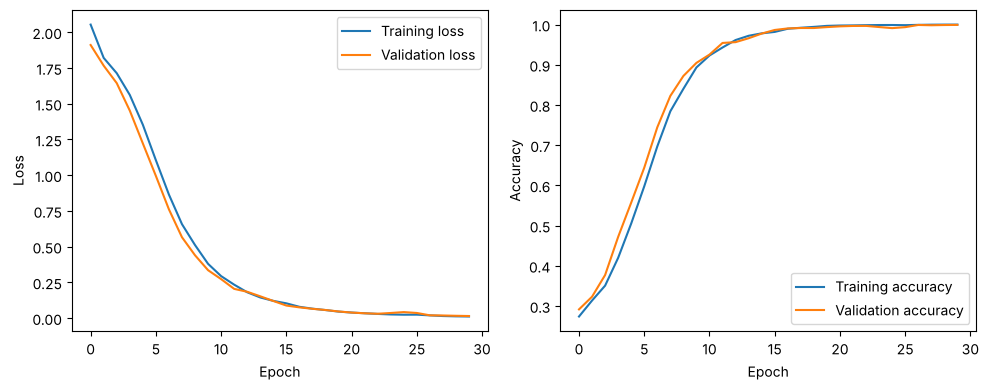

In [14]:
def build_amount_model(units):
    enc_input = Input(shape=(a_max_in,), name='encoder_input')
    enc_emb = Embedding(a_in_vocab, 32, mask_zero=True, name='encoder_embedding')(enc_input)
    _, state_h, state_c = LSTM(units, return_state=True, name='encoder_lstm')(enc_emb)
    dec_input = Input(shape=(None,), name='decoder_input')
    dec_emb = Embedding(a_out_vocab, 32, name='decoder_embedding')(dec_input)
    dec_seq, _, _ = LSTM(units, return_sequences=True, return_state=True, name='decoder_lstm')(dec_emb, initial_state=[state_h, state_c])
    output = Dense(a_out_vocab, activation='softmax', name='output')(dec_seq)
    model = Model([enc_input, dec_input], output)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def translate_amount(model, X):
    dec = np.full((len(X), 1), a_start)
    for _ in range(a_out_len):
        probs = model([X, dec], training=False).numpy()
        dec = np.concatenate([dec, probs[:, -1, :].argmax(axis=-1)[:, None]], axis=1)
    return dec[:, 1:]

def amount_text(ids):
    return ''.join(a_inv_out.get(i, '?') for i in ids).replace('$', '')

amount_model = build_amount_model(128)
amount_model.summary()
amount_history = amount_model.fit([a_X_train, a_y_in_train], a_y_train, epochs=30, batch_size=128, validation_split=0.1, verbose=2)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(amount_history.history['loss'], label='Training loss')
plt.plot(amount_history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(amount_history.history['accuracy'], label='Training accuracy')
plt.plot(amount_history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

- **encoder_input**: receives the amount in words as a padded sequence of character ids.
- **encoder_embedding**: turns every character id into a 32-number vector; mask_zero=True makes the LSTM skip the padding.
- **encoder_lstm**: reads the characters one by one and keeps only its final hidden state and cell state, which together form the context vector that summarises the whole amount.
- **decoder_input**: receives the start token followed by the correct previous digits (teacher forcing).
- **decoder_embedding**: turns every output id into a 32-number vector.
- **decoder_lstm**: starts from the context vector and produces one hidden state for each of the 7 output positions.
- **output (Dense + softmax)**: gives a probability for each of the 13 output symbols (digits, the end/padding symbol '$', padding id and start token) at every position.

### Task 4: Exact-match and character accuracy

In [15]:
a_pred = translate_amount(amount_model, a_X_test)
print('Exact-match accuracy:', round(float(np.mean(np.all(a_pred == a_y_test, axis=1))), 4))
print('Character accuracy  :', round(float(np.mean(a_pred == a_y_test)), 4))

amount_test = amount_df.iloc[10000:].copy()
amount_test['predicted'] = [amount_text(p) for p in a_pred]
amount_test['correct'] = amount_test['predicted'] == amount_test['amount_digits']
print(amount_test.sample(10, random_state=1).to_string())
print(amount_test[~amount_test['correct']].head(10).to_string())

Exact-match accuracy: 0.995
Character accuracy  : 0.9986
                                                           amount_words amount_digits predicted  correct
10674             nine hundred twenty thousand three hundred twenty one        920321    920321     True
11699      nine hundred thirty four thousand seven hundred thirty eight        934738    934738     True
11282                                        six hundred and sixty five           665       665     True
11315  six hundred and sixty six thousand seven hundred and fifty three        666753    666753     True
11210                  two hundred sixty one thousand six hundred three        261603    261603     True
11636                   seventy seven thousand nine hundred sixty eight         77968     77968     True
10613                               one thousand two hundred twenty one          1221      1221     True
10447              two hundred seventy thousand one hundred forty three        270143    270143     Tru

### Task 5: Size of the context vector

   Units  Context vector size  Parameters  Exact-match accuracy  \
0     32                   64       18125                0.4000   
1     64                  128       51565                0.7630   
2    128                  256      167597                0.9950   
3    256                  512      596269                0.9965   

   Character accuracy  
0              0.7215  
1              0.9176  
2              0.9986  
3              0.9991  


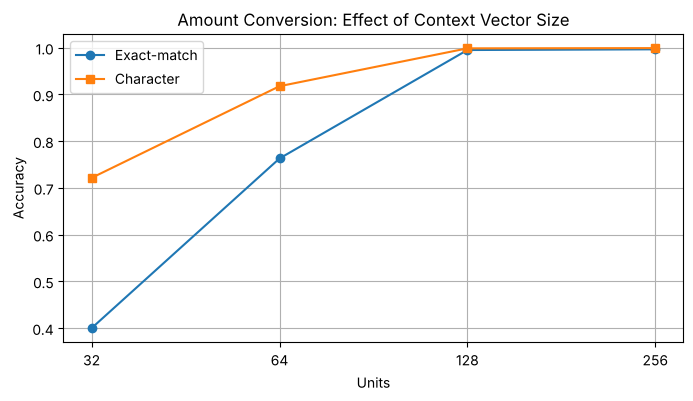

In [16]:
amount_units = []
for u in [32, 64, 128, 256]:
    if u == 128:
        p = a_pred
        params = amount_model.count_params()
    else:
        m = build_amount_model(u)
        m.fit([a_X_train, a_y_in_train], a_y_train, epochs=30, batch_size=128, validation_split=0.1, verbose=0)
        p = translate_amount(m, a_X_test)
        params = m.count_params()
    amount_units.append({
        'Units': u,
        'Context vector size': 2 * u,
        'Parameters': params,
        'Exact-match accuracy': round(float(np.mean(np.all(p == a_y_test, axis=1))), 4),
        'Character accuracy': round(float(np.mean(p == a_y_test)), 4)
    })
amount_units_df = pd.DataFrame(amount_units)
print(amount_units_df)

plt.figure(figsize=(8, 4))
plt.plot(amount_units_df['Units'], amount_units_df['Exact-match accuracy'], marker='o', label='Exact-match')
plt.plot(amount_units_df['Units'], amount_units_df['Character accuracy'], marker='s', label='Character')
plt.xscale('log', base=2)
plt.xticks(amount_units_df['Units'], amount_units_df['Units'])
plt.xlabel('Units')
plt.ylabel('Accuracy')
plt.title('Amount Conversion: Effect of Context Vector Size')
plt.legend()
plt.grid(True)
plt.show()

### Task 6: Conclusion

A finance department can use this model to read the amount in words on cheques, invoices, purchase orders and contracts and convert it into digits automatically. The converted value can then be compared with the amount written in figures, so that any mismatch is flagged before payment, which is a standard control against fraud and data-entry mistakes. The model removes repetitive manual typing and can be retrained when new wording appears, without rewriting rules.

The risk of a wrong output is high, because an amount with one wrong, swapped or extra digit can be far from the true value; for example the model turned 420004 into 4200004 and 32 into 302. The experiments show that a larger context vector strongly improves exact-match accuracy, from 0.40 at 32 units and 0.763 at 64 units to 0.995 at 128 units, after which it levels off (0.9965 at 256 units) while the parameters grow from about 168,000 to 596,000. Even the best model still makes a few errors, mostly swapped or misplaced digits. For this reason the model should not post payments by itself: every converted amount should be checked against the figure written in digits, and any mismatch or unusual amount should be sent to a person for approval. Used this way, the model saves time while the business keeps control over financial risk.

# Lab 10: Seq2Seq with Attention vs without Attention

## Step 1: Compute attention by hand

In [17]:
import numpy as np

words = ['the', 'delivery', 'was', 'very', 'late']
encoder_states = np.array([
    [0.1, 0.0, 0.2],
    [0.9, 0.1, 0.3],
    [0.0, 0.1, 0.1],
    [0.2, 0.6, 0.1],
    [0.8, 0.9, 0.2]
])
decoder_state = np.array([1.0, 1.0, 0.0])

scores = encoder_states @ decoder_state
weights = np.exp(scores) / np.exp(scores).sum()
context = weights @ encoder_states
for w, s, a in zip(words, scores, weights):
    print(f'{w:10s} score={s:.2f} weight={a:.2f}')
print('Context vector:', context.round(3))

the        score=0.10 weight=0.09
delivery   score=1.00 weight=0.22
was        score=0.10 weight=0.09
very       score=0.80 weight=0.18
late       score=1.70 weight=0.43
Context vector: [0.585 0.526 0.195]


## Step 2: Import libraries and recreate the data

In [18]:
import time
import random
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Attention, Concatenate
from tensorflow.keras.preprocessing.sequence import pad_sequences

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

formats = ['%d %B %Y', '%d %b %Y', '%B %d, %Y', '%d/%m/%Y', '%d.%m.%y', '%A, %d %B %Y', '%b %d %Y', '%d-%b-%y']

def random_date():
    d = datetime.date(1990, 1, 1) + datetime.timedelta(days=random.randint(0, 14600))
    return d.strftime(random.choice(formats)).lower(), d.isoformat()

df = pd.DataFrame([random_date() for _ in range(20000)], columns=['invoice_date', 'standard_date'])

in_chars = sorted(set(''.join(df['invoice_date'])))
out_chars = sorted(set(''.join(df['standard_date'])))
in_index = {c: i + 1 for i, c in enumerate(in_chars)}
out_index = {c: i + 1 for i, c in enumerate(out_chars)}
inv_out = {i: c for c, i in out_index.items()}
start_id = len(out_chars) + 1
in_vocab = len(in_chars) + 1
out_vocab = len(out_chars) + 2

max_in = 30
X = pad_sequences([[in_index[c] for c in s] for s in df['invoice_date']], maxlen=max_in, padding='post')
y = np.array([[out_index[c] for c in s] for s in df['standard_date']])
y_in = np.concatenate([np.full((len(y), 1), start_id), y[:, :-1]], axis=1)

X_train, X_test = X[:16000], X[16000:]
y_train, y_test = y[:16000], y[16000:]
y_in_train, y_in_test = y_in[:16000], y_in[16000:]

def translate(model, X):
    dec = np.full((len(X), 1), start_id)
    for _ in range(10):
        probs = model([X, dec], training=False).numpy()
        next_id = probs[:, -1, :].argmax(axis=-1)
        dec = np.concatenate([dec, next_id[:, None]], axis=1)
    return dec[:, 1:]

def to_text(ids):
    return ''.join(inv_out.get(i, '?') for i in ids)

## Step 3: Define one function for both models

In [19]:
units = 32

def build_model(use_attention):
    enc_input = Input(shape=(max_in,), name='encoder_input')
    enc_emb = Embedding(in_vocab, 32, mask_zero=True)(enc_input)
    enc_seq, state_h, state_c = LSTM(units, return_sequences=True, return_state=True, name='encoder_lstm')(enc_emb)
    dec_input = Input(shape=(None,), name='decoder_input')
    dec_emb = Embedding(out_vocab, 32)(dec_input)
    dec_seq, _, _ = LSTM(units, return_sequences=True, return_state=True, name='decoder_lstm')(dec_emb, initial_state=[state_h, state_c])
    score_model = None
    if use_attention:
        context, scores = Attention(name='attention')([dec_seq, enc_seq], return_attention_scores=True)
        dec_seq = Concatenate(name='concat')([dec_seq, context])
        score_model = Model([enc_input, dec_input], scores)
    output = Dense(out_vocab, activation='softmax', name='output')(dec_seq)
    model = Model([enc_input, dec_input], output)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model, score_model

base_model, _ = build_model(use_attention=False)
attn_model, score_model = build_model(use_attention=True)
base_model.summary()
attn_model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_14        │ (None, 30, 32)    │      1,216 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_11        │ (None, 30)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_15        │ (None, None, 32)  │        416 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 30, 32),  │      8,320 │ embedding_14[0][… │
│                     │ (None, 32),       │            │ not_equal_11[0][… │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │      8,320 │ embedding_15[0][… │
│                     │ 32), (None, 32),  │            │ encoder_lstm[0][… │
│                     │ (None, 32)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None, 13)  │        429 │ decoder_lstm[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,701 (73.05 KB)

 Trainable params: 18,701 (73.05 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_16        │ (None, 30, 32)    │      1,216 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_12        │ (None, 30)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_17        │ (None, None, 32)  │        416 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 30, 32),  │      8,320 │ embedding_16[0][… │
│                     │ (None, 32),       │            │ not_equal_12[0][… │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │      8,320 │ embedding_17[0][… │
│                     │ 32), (None, 32),  │            │ encoder_lstm[0][… │
│                     │ (None, 32)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, None,     │          0 │ decoder_lstm[0][… │
│ (Attention)         │ 32), (None, None, │            │ encoder_lstm[0][… │
│                     │ 30)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, None, 64)  │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None, 13)  │        845 │ concat[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,117 (74.68 KB)

 Trainable params: 19,117 (74.68 KB)

 Non-trainable params: 0 (0.00 B)

## Step 4: Train both models

In [20]:
def train(model):
    start = time.time()
    history = model.fit(
        [X_train, y_in_train], y_train,
        epochs=20, batch_size=128,
        validation_split=0.1, verbose=2
    )
    return history, time.time() - start

base_history, base_time = train(base_model)
attn_history, attn_time = train(attn_model)

Epoch 1/20


113/113 - 10s - 86ms/step - accuracy: 0.4889 - loss: 1.7262 - val_accuracy: 0.5984 - val_loss: 1.1915


Epoch 2/20


113/113 - 4s - 33ms/step - accuracy: 0.6576 - loss: 0.9999 - val_accuracy: 0.7094 - val_loss: 0.8444


Epoch 3/20


...

113/113 - 4s - 38ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0031


Epoch 19/20


113/113 - 4s - 35ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 1.0000 - val_loss: 0.0027


Epoch 20/20


113/113 - 4s - 39ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 1.0000 - val_loss: 0.0023


## Step 5: Compare the results

                 Model  Parameters  Exact-match accuracy  Character accuracy  \
0              Seq2Seq       18701                0.9192              0.9795   
1  Seq2Seq + Attention       19117                1.0000              1.0000   

   Training time (s)  
0               82.8  
1               89.2  


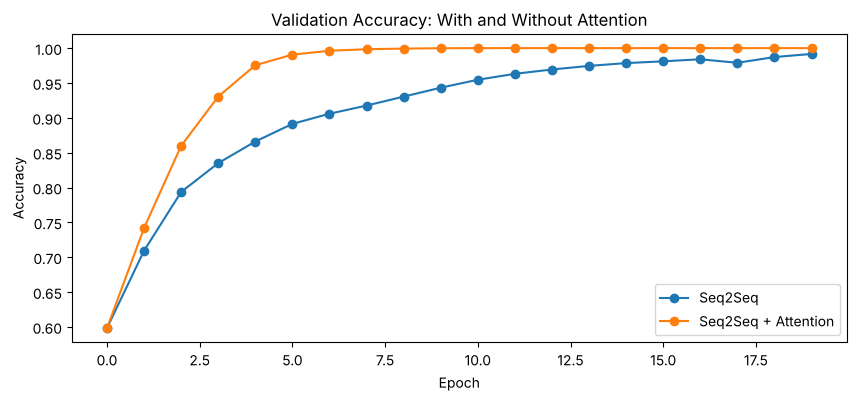

In [21]:
base_pred = translate(base_model, X_test)
attn_pred = translate(attn_model, X_test)

results = pd.DataFrame({
    'Model': ['Seq2Seq', 'Seq2Seq + Attention'],
    'Parameters': [base_model.count_params(), attn_model.count_params()],
    'Exact-match accuracy': [np.mean(np.all(base_pred == y_test, axis=1)).round(4), np.mean(np.all(attn_pred == y_test, axis=1)).round(4)],
    'Character accuracy': [np.mean(base_pred == y_test).round(4), np.mean(attn_pred == y_test).round(4)],
    'Training time (s)': [round(base_time, 1), round(attn_time, 1)]
})
print(results)

plt.figure(figsize=(10, 4))
plt.plot(base_history.history['val_accuracy'], marker='o', label='Seq2Seq')
plt.plot(attn_history.history['val_accuracy'], marker='o', label='Seq2Seq + Attention')
plt.title('Validation Accuracy: With and Without Attention')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Step 6: See where the model looks

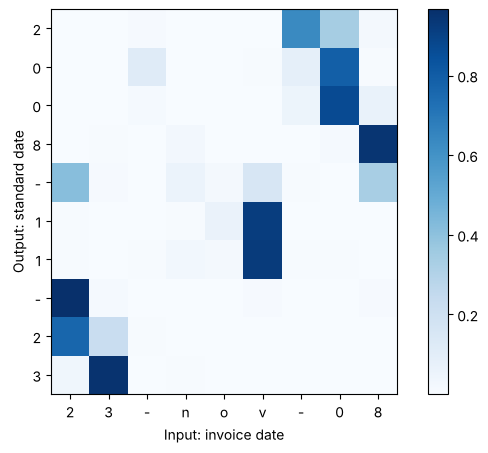

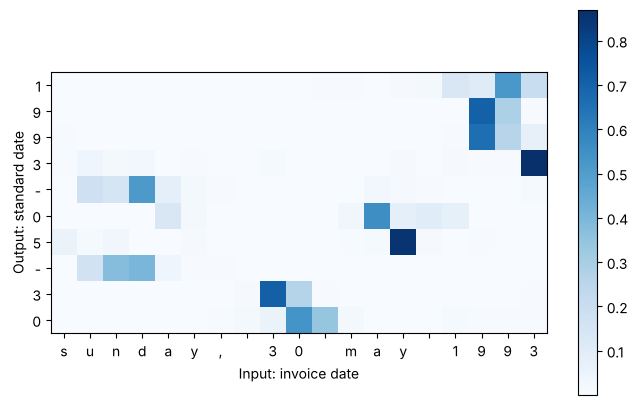

In [22]:
def show_attention(i):
    text = df['invoice_date'].iloc[16000 + i]
    out_ids = translate(attn_model, X_test[i:i + 1])[0]
    dec = np.concatenate([[start_id], out_ids[:-1]])[None, :]
    weights = score_model([X_test[i:i + 1], dec], training=False).numpy()[0][:, :len(text)]
    plt.figure(figsize=(8, 5))
    plt.imshow(weights, cmap='Blues')
    plt.xticks(range(len(text)), list(text))
    plt.yticks(range(10), list(to_text(out_ids)))
    plt.xlabel('Input: invoice date')
    plt.ylabel('Output: standard date')
    plt.colorbar()
    plt.show()

show_attention(0)
show_attention(5)

## Step 7: Test on your own invoice dates

In [23]:
def standardise(texts, model):
    ids = pad_sequences([[in_index.get(c, 0) for c in t.lower()] for t in texts], maxlen=max_in, padding='post')
    return [to_text(p) for p in translate(model, ids)]

samples = ['3 march 2021', 'dec 25 2019', '01/07/2024', 'friday, 14 june 2002']
print(pd.DataFrame({
    'Input': samples,
    'Seq2Seq': standardise(samples, base_model),
    'Seq2Seq + Attention': standardise(samples, attn_model)
}))

                  Input     Seq2Seq Seq2Seq + Attention
0          3 march 2021  2023-03-31          2021-03-31
1           dec 25 2019  2019-12-25          2019-12-25
2            01/07/2024  2024-07-01          2024-07-01
3  friday, 14 june 2002  2002-06-14          2002-06-14


## Lab 10 Task 1: Attention heatmaps for three formats

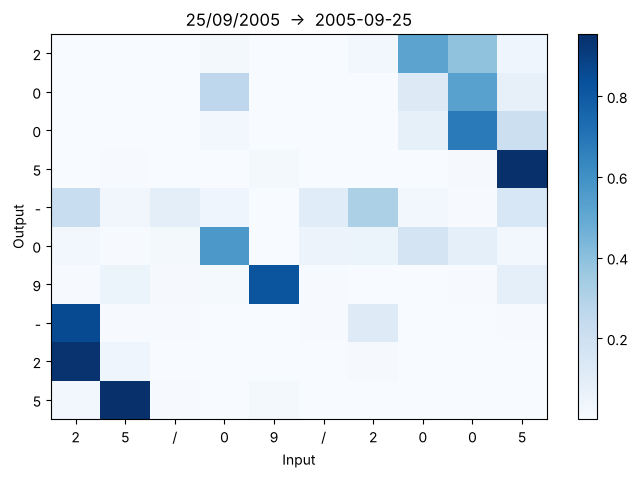

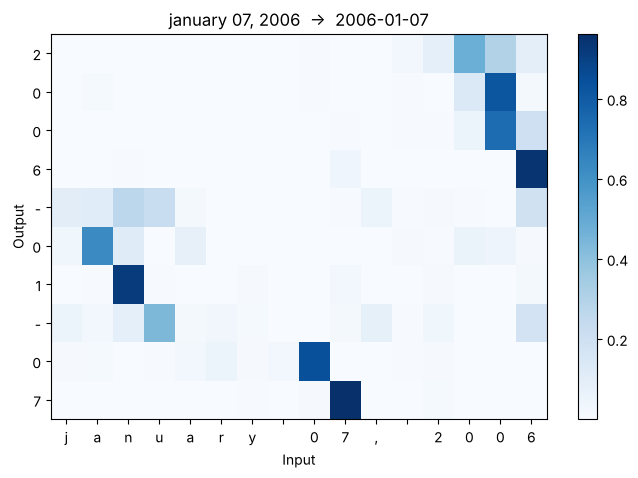

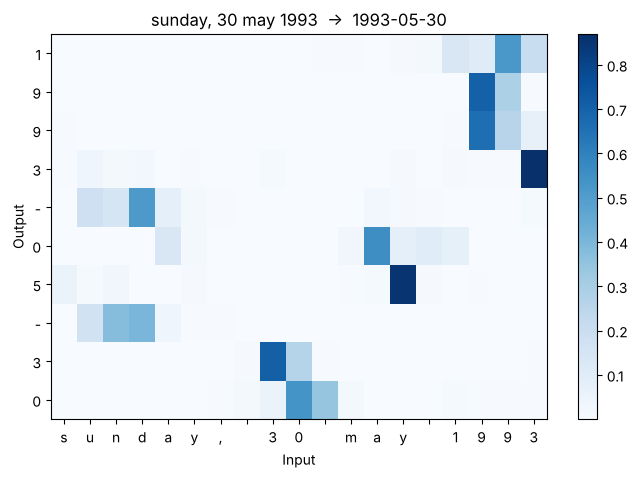

Average share of attention on the weekday name: 0.181


In [24]:
from tensorflow.keras.layers import AdditiveAttention

def find_format(s):
    for f in formats:
        try:
            datetime.datetime.strptime(s, f)
            return f
        except ValueError:
            pass
    return 'unknown'

def translate_gen(model, X, start, steps):
    dec = np.full((len(X), 1), start)
    for _ in range(steps):
        probs = model([X, dec], training=False).numpy()
        dec = np.concatenate([dec, probs[:, -1, :].argmax(axis=-1)[:, None]], axis=1)
    return dec[:, 1:]

def plot_attention(model, smodel, x_row, text, start, steps, idx_to_char, title=''):
    out_ids = translate_gen(model, x_row[None, :], start, steps)[0]
    dec = np.concatenate([[start], out_ids[:-1]])[None, :]
    w = smodel([x_row[None, :], dec], training=False).numpy()[0][:, :len(text)]
    out_text = ''.join(idx_to_char.get(i, '?') for i in out_ids)
    plt.figure(figsize=(max(8, len(text) * 0.32), 5))
    plt.imshow(w, cmap='Blues', aspect='auto')
    plt.xticks(range(len(text)), list(text))
    plt.yticks(range(steps), list(out_text))
    plt.title(title)
    plt.xlabel('Input')
    plt.ylabel('Output')
    plt.colorbar()
    plt.show()

lab10_test = df.iloc[16000:].copy().reset_index(drop=True)
lab10_test['format'] = lab10_test['invoice_date'].apply(find_format)

for f in ['%d/%m/%Y', '%B %d, %Y', '%A, %d %B %Y']:
    i = int(np.where(lab10_test['format'].values == f)[0][0])
    plot_attention(attn_model, score_model, X_test[i], lab10_test['invoice_date'].iloc[i], start_id, 10, inv_out,
                   title=f"{lab10_test['invoice_date'].iloc[i]}  ->  {lab10_test['standard_date'].iloc[i]}")

wk_idx = np.where(lab10_test['format'].values == '%A, %d %B %Y')[0][:300]
wk_w = score_model([X_test[wk_idx], y_in_test[wk_idx]], training=False).numpy()
wk_mass = [wk_w[k][:, :lab10_test['invoice_date'].iloc[j].index(',')].sum(axis=1).mean() for k, j in enumerate(wk_idx)]
print('Average share of attention on the weekday name:', round(float(np.mean(wk_mass)), 3))

- **dd/mm/yyyy (25/09/2005)**: when writing the year the model looks at the last four digits, when writing the month it looks at the '0' and '9' after the first '/', and when writing the day it looks at the first two digits.
- **Month name first (january 07, 2006)**: the year comes from the four digits after the comma, the month from the letters of the month name (mainly 'a' and 'n'), and the day from the two digits before the comma.
- **Weekday format (sunday, 30 may 1993)**: the digits of the output look at the day digits, the end of the month word and the year digits. The weekday name is not ignored completely: it receives 0.181 of the attention on average, but almost all of that comes from the two '-' separators in the output, which have no clear source in the input. The day, month and year digits put almost no weight on the weekday name, because it adds no information that is not already in the date.

## Lab 10 Task 2: Additive (Bahdanau) attention

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 30)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_18        │ (None, 30, 32)    │      1,216 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_13        │ (None, 30)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_19        │ (None, None, 32)  │        416 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 30, 32),  │      8,320 │ embedding_18[0][… │
│                     │ (None, 32),       │            │ not_equal_13[0][… │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │      8,320 │ embedding_19[0][… │
│                     │ 32), (None, 32),  │            │ encoder_lstm[0][… │
│                     │ (None, 32)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, None,     │         32 │ decoder_lstm[0][… │
│ (AdditiveAttention) │ 32), (None, None, │            │ encoder_lstm[0][… │
│                     │ 30)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat              │ (None, None, 64)  │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, None, 13)  │        845 │ concat[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,149 (74.80 KB)

 Trainable params: 19,149 (74.80 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 19/20


113/113 - 5s - 43ms/step - accuracy: 0.9966 - loss: 0.0287 - val_accuracy: 0.9952 - val_loss: 0.0282


Epoch 20/20


113/113 - 5s - 43ms/step - accuracy: 0.9972 - loss: 0.0247 - val_accuracy: 0.9959 - val_loss: 0.0249


                          Model  Parameters  Exact-match accuracy  \
0                       Seq2Seq       18701                0.9192   
1           Seq2Seq + Attention       19117                1.0000   
2  Seq2Seq + Additive Attention       19149                0.9625   

   Character accuracy  Training time (s)  Mean max attention weight  
0              0.9795               82.8                        NaN  
1              1.0000               89.2                      0.674  
2              0.9913              104.0                      0.346  


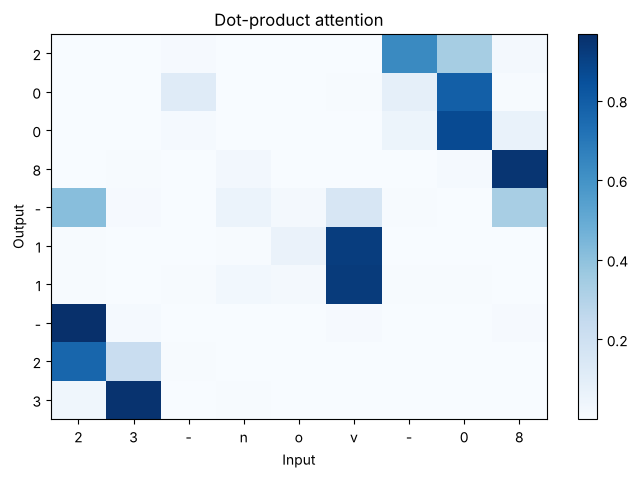

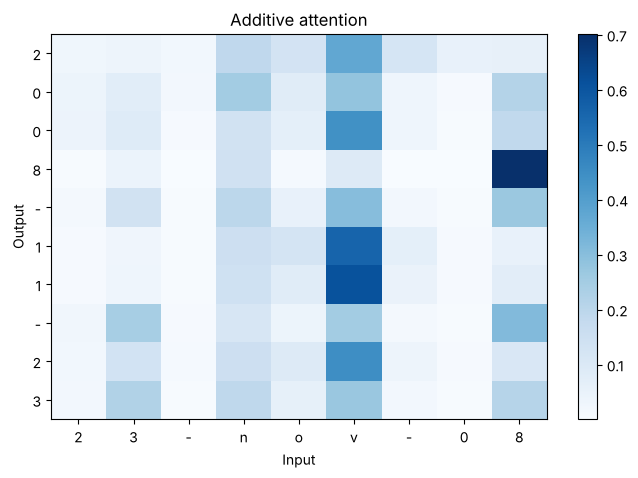

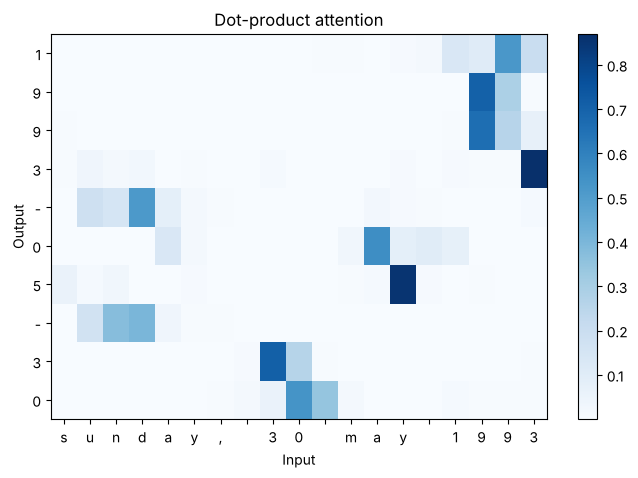

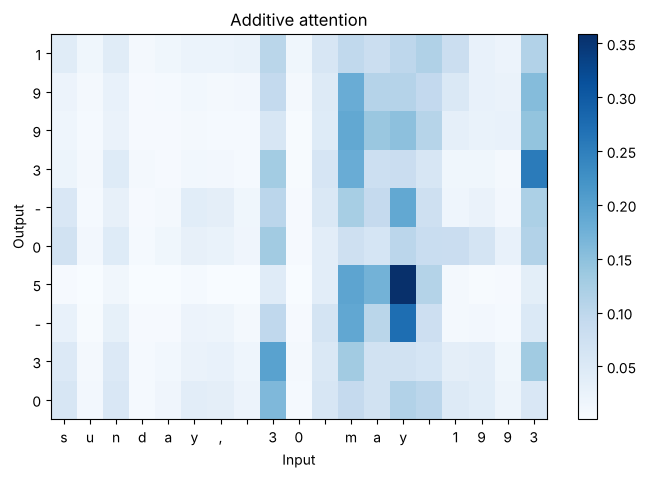

In [25]:
def build_any(kind, n_units, max_len, in_v, out_v):
    enc_input = Input(shape=(max_len,), name='encoder_input')
    enc_emb = Embedding(in_v, 32, mask_zero=True)(enc_input)
    enc_seq, state_h, state_c = LSTM(n_units, return_sequences=True, return_state=True, name='encoder_lstm')(enc_emb)
    dec_input = Input(shape=(None,), name='decoder_input')
    dec_emb = Embedding(out_v, 32)(dec_input)
    dec_seq, _, _ = LSTM(n_units, return_sequences=True, return_state=True, name='decoder_lstm')(dec_emb, initial_state=[state_h, state_c])
    score_model = None
    if kind != 'none':
        layer = Attention(name='attention') if kind == 'dot' else AdditiveAttention(name='attention')
        context, scores = layer([dec_seq, enc_seq], return_attention_scores=True)
        dec_seq = Concatenate(name='concat')([dec_seq, context])
        score_model = Model([enc_input, dec_input], scores)
    output = Dense(out_v, activation='softmax', name='output')(dec_seq)
    model = Model([enc_input, dec_input], output)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model, score_model

add_model, add_score = build_any('additive', units, max_in, in_vocab, out_vocab)
add_model.summary()
add_history, add_time = train(add_model)
add_pred = translate(add_model, X_test)

results.loc[len(results)] = ['Seq2Seq + Additive Attention', add_model.count_params(),
                             np.mean(np.all(add_pred == y_test, axis=1)).round(4),
                             np.mean(add_pred == y_test).round(4), round(add_time, 1)]

def sharpness(smodel, n=500):
    w = smodel([X_test[:n], y_in_test[:n]], training=False).numpy()
    return round(float(w.max(axis=-1).mean()), 3)

results['Mean max attention weight'] = [np.nan, sharpness(score_model), sharpness(add_score)]
print(results)

for i in [0, 5]:
    plot_attention(attn_model, score_model, X_test[i], lab10_test['invoice_date'].iloc[i], start_id, 10, inv_out, title='Dot-product attention')
    plot_attention(add_model, add_score, X_test[i], lab10_test['invoice_date'].iloc[i], start_id, 10, inv_out, title='Additive attention')

Additive attention scores each pair of decoder and encoder states with a small learned network, so it adds a few parameters (19,149 against 19,117), while dot-product attention has none. Both beat the model without attention (0.9192), but dot-product attention is clearly better here: it reaches 1.0 exact-match accuracy against 0.9625 for additive attention, and it also trains faster. The mean max attention weight measures how sharp the heatmaps are: a value near 1 means the model puts almost all of its attention on one input character. Dot-product attention is much sharper (0.674 against 0.346), and its heatmaps show clean, focused blocks on the right characters. Additive attention spreads its weight over several characters, for example the month letters, but still gets most dates right.

## Lab 10 Task 3: 16, 32 and 64 units

   Units  Seq2Seq  Seq2Seq + Attention     Gap
0     16   0.1928                0.961  0.7682
1     32   0.9193                1.000  0.0807
2     64   0.9940                1.000  0.0060


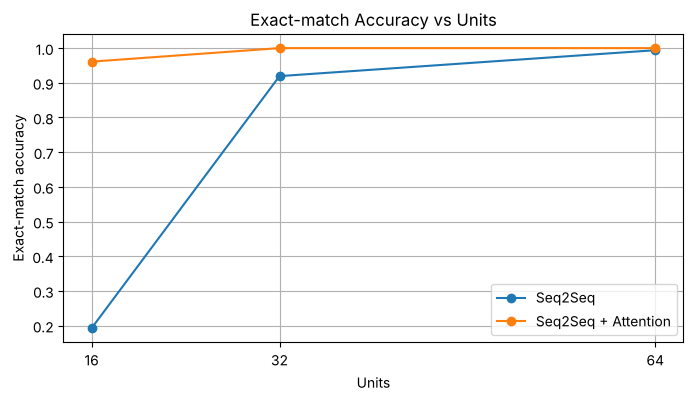

In [26]:
size_rows = []
for u in [16, 32, 64]:
    row = {'Units': u}
    for kind, label in [('none', 'Seq2Seq'), ('dot', 'Seq2Seq + Attention')]:
        if u == 32:
            p = base_pred if kind == 'none' else attn_pred
        else:
            m, _ = build_any(kind, u, max_in, in_vocab, out_vocab)
            m.fit([X_train, y_in_train], y_train, epochs=20, batch_size=128, validation_split=0.1, verbose=0)
            p = translate(m, X_test)
        row[label] = round(float(np.mean(np.all(p == y_test, axis=1))), 4)
    size_rows.append(row)
size_df = pd.DataFrame(size_rows)
size_df['Gap'] = (size_df['Seq2Seq + Attention'] - size_df['Seq2Seq']).round(4)
print(size_df)

plt.figure(figsize=(8, 4))
plt.plot(size_df['Units'], size_df['Seq2Seq'], marker='o', label='Seq2Seq')
plt.plot(size_df['Units'], size_df['Seq2Seq + Attention'], marker='o', label='Seq2Seq + Attention')
plt.xticks(size_df['Units'])
plt.title('Exact-match Accuracy vs Units')
plt.xlabel('Units')
plt.ylabel('Exact-match accuracy')
plt.legend()
plt.grid(True)
plt.show()

Without attention the decoder sees only the final encoder state, so everything about the input must fit into 2 x units numbers. With 16 units this context vector is far too small and exact-match accuracy drops to 0.1928; it recovers to 0.9193 at 32 units and 0.994 at 64 units. With attention the decoder can read all 30 encoder states again at every output step, so it does not depend on one fixed summary. Its accuracy stays high even at 16 units (0.961) and is 1.0 at 32 and 64 units. The gap between the two models is largest for the smallest model (0.7682 at 16 units) and narrows as the context vector grows (0.0807 at 32 and 0.006 at 64). This shows that attention removes the context-vector bottleneck from Lab 9.

## Lab 10 Task 4: Recommendation

In [27]:
monthly = 50000
rec = results[['Model', 'Exact-match accuracy', 'Training time (s)']].copy()
rec['Wrong dates per month'] = ((1 - rec['Exact-match accuracy'].astype(float)) * monthly).round().astype(int)
print(rec)

                          Model  Exact-match accuracy  Training time (s)  \
0                       Seq2Seq                0.9192               82.8   
1           Seq2Seq + Attention                1.0000               89.2   
2  Seq2Seq + Additive Attention                0.9625              104.0   

   Wrong dates per month  
0                   4040  
1                      0  
2                   1875  


The recommended model is seq2seq with dot-product attention. At 50,000 invoices a month it is expected to produce 0 wrong dates on this test data, against 4,040 for the model without attention and 1,875 for additive attention, which directly reduces payment errors and manual correction work. It adds only 416 parameters and about 6 seconds of training time (89.2 s against 82.8 s), which is negligible because the model is trained once and then used many times. Additive attention is less accurate, has more parameters and is the slowest to train. Most importantly, the attention heatmaps show which characters were used for the day, month and year, so auditors can check why a particular date was produced. Outputs that fail a date validity check should still be sent for human review.

## Lab Assignment 4: Attention-based sequence model comparison study

### Task 1: Three models under the same settings (standard invoice dates)

In [28]:
short_rows = []
for name, m, p, t in [('Seq2Seq', base_model, base_pred, base_time),
                      ('Seq2Seq + Dot Attention', attn_model, attn_pred, attn_time),
                      ('Seq2Seq + Additive Attention', add_model, add_pred, add_time)]:
    short_rows.append({
        'Input': 'Date only',
        'Model': name,
        'Parameters': m.count_params(),
        'Exact-match accuracy': round(float(np.mean(np.all(p == y_test, axis=1))), 4),
        'Character accuracy': round(float(np.mean(p == y_test)), 4),
        'Training time (s)': round(t, 1)
    })
print(pd.DataFrame(short_rows))

       Input                         Model  Parameters  Exact-match accuracy  \
0  Date only                       Seq2Seq       18701                0.9193   
1  Date only       Seq2Seq + Dot Attention       19117                1.0000   
2  Date only  Seq2Seq + Additive Attention       19149                0.9625   

   Character accuracy  Training time (s)  
0              0.9795               82.8  
1              1.0000               89.2  
2              0.9913              104.0  


### Task 2: Longer inputs (supplier name and invoice number before the date)

                                           invoice_text standard_date
0  invoice 52750 from nishat textiles dated 07 sep 2018    2018-09-07
1                karachi steel works inv-71239 14.02.91    1991-02-14
2                     packages ltd inv-77387 26/12/2000    2000-12-26
3                 habib oil mills inv-29140 05 apr 1996    1996-04-05
4             karachi steel works inv-57838 10 may 2020    2020-05-10
5       karachi steel works, bill no 32544, jun 27 2016    2016-06-27
6                habib oil mills inv-56642 05 june 1991    1991-06-05
7                  sapphire fibres inv-17226 16/03/1994    1994-03-16
count    20000.000000
mean        45.932750
std          7.503002
min         30.000000
25%         41.000000
50%         45.500000
75%         51.000000
max         73.000000
Name: invoice_text, dtype: float64
Input vocabulary: 44  max length: 75  shapes: (16000, 75) (4000, 75)


Epoch 1/20


113/113 - 13s - 116ms/step - accuracy: 0.4460 - loss: 1.7538 - val_accuracy: 0.5838 - val_loss: 1.2409


Epoch 2/20


113/113 - 8s - 69ms/step - accuracy: 0.6317 - loss: 1.0494 - val_accuracy: 0.6819 - val_loss: 0.8963


...

113/113 - 9s - 83ms/step - accuracy: 0.9677 - loss: 0.1097 - val_accuracy: 0.9704 - val_loss: 0.1044


Epoch 19/20


113/113 - 9s - 80ms/step - accuracy: 0.9722 - loss: 0.0976 - val_accuracy: 0.9725 - val_loss: 0.0955


Epoch 20/20


113/113 - 9s - 82ms/step - accuracy: 0.9757 - loss: 0.0871 - val_accuracy: 0.9755 - val_loss: 0.0876


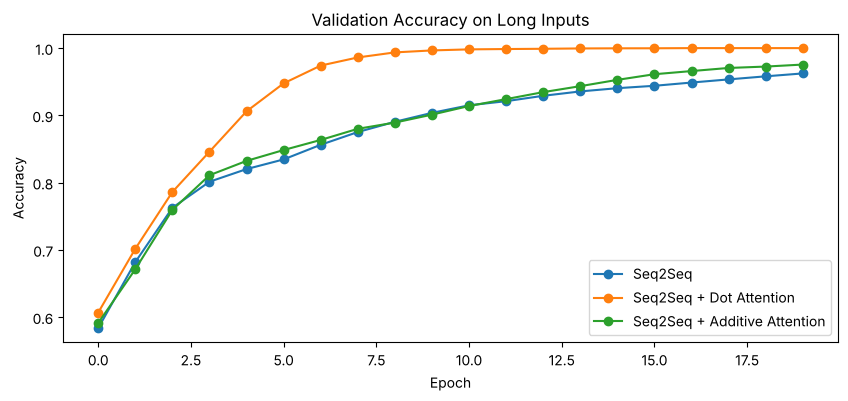

In [29]:
random.seed(7)
np.random.seed(7)
tf.random.set_seed(7)

suppliers = ['al-falah traders', 'karachi steel works', 'nishat textiles', 'zamzam foods', 'quetta marble co',
             'packages ltd', 'lucky cement', 'engro fertilizers', 'habib oil mills', 'sapphire fibres',
             'hashoo logistics', 'kohinoor mills']
templates = ['{s} inv-{n} {d}', '{s} | invoice #{n} | {d}', 'invoice {n} from {s} dated {d}', '{s}, bill no {n}, {d}']

long_df = pd.DataFrame({
    'invoice_text': [random.choice(templates).format(s=random.choice(suppliers), n=random.randint(1000, 99999), d=d) for d in df['invoice_date']],
    'standard_date': df['standard_date']
})
print(long_df.head(8).to_string())
print(long_df['invoice_text'].str.len().describe())

l_chars = sorted(set(''.join(long_df['invoice_text'])))
l_index = {c: i + 1 for i, c in enumerate(l_chars)}
l_vocab = len(l_chars) + 1
max_long = int(long_df['invoice_text'].str.len().max()) + 2

XL = pad_sequences([[l_index[c] for c in s] for s in long_df['invoice_text']], maxlen=max_long, padding='post')
XL_train, XL_test = XL[:16000], XL[16000:]
print('Input vocabulary:', l_vocab, ' max length:', max_long, ' shapes:', XL_train.shape, XL_test.shape)

def train_long(model):
    start = time.time()
    history = model.fit([XL_train, y_in_train], y_train, epochs=20, batch_size=128, validation_split=0.1, verbose=2)
    return history, time.time() - start

long_models = {}
for kind, name in [('none', 'Seq2Seq'), ('dot', 'Seq2Seq + Dot Attention'), ('additive', 'Seq2Seq + Additive Attention')]:
    m, sm = build_any(kind, units, max_long, l_vocab, out_vocab)
    h, t = train_long(m)
    p = translate_gen(m, XL_test, start_id, 10)
    long_models[name] = {'model': m, 'score_model': sm, 'history': h, 'time': t, 'pred': p}

plt.figure(figsize=(10, 4))
for name, r in long_models.items():
    plt.plot(r['history'].history['val_accuracy'], marker='o', label=name)
plt.title('Validation Accuracy on Long Inputs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

### Task 3: Results table

                       Input                        Model  Parameters  Exact-match accuracy  Character accuracy  Training time (s)
                   Date only                      Seq2Seq       18701                0.9193              0.9795               82.8
                   Date only      Seq2Seq + Dot Attention       19117                1.0000              1.0000               89.2
                   Date only Seq2Seq + Additive Attention       19149                0.9625              0.9913              104.0
Supplier + invoice no + date                      Seq2Seq       18893                0.6478              0.9270              160.3
Supplier + invoice no + date      Seq2Seq + Dot Attention       19309                0.9992              0.9998              169.7
Supplier + invoice no + date Seq2Seq + Additive Attention       19341                0.7612              0.9497              198.6


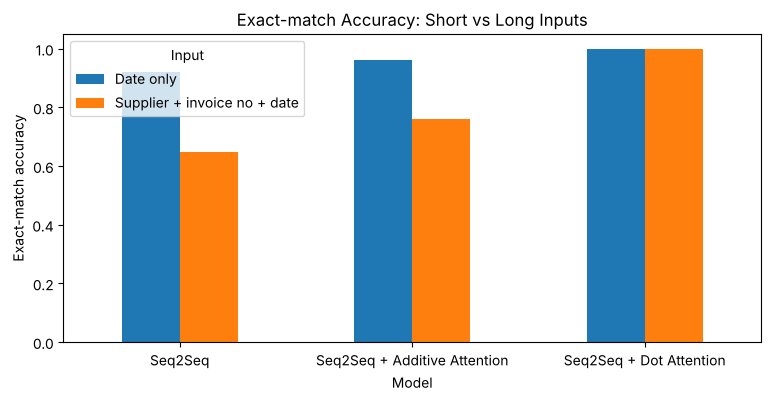

In [30]:
long_rows = []
for name, r in long_models.items():
    long_rows.append({
        'Input': 'Supplier + invoice no + date',
        'Model': name,
        'Parameters': r['model'].count_params(),
        'Exact-match accuracy': round(float(np.mean(np.all(r['pred'] == y_test, axis=1))), 4),
        'Character accuracy': round(float(np.mean(r['pred'] == y_test)), 4),
        'Training time (s)': round(r['time'], 1)
    })
study = pd.DataFrame(short_rows + long_rows)
print(study.to_string(index=False))

pivot = study.pivot(index='Model', columns='Input', values='Exact-match accuracy')
pivot.plot(kind='bar', figsize=(9, 4), rot=0)
plt.title('Exact-match Accuracy: Short vs Long Inputs')
plt.ylabel('Exact-match accuracy')
plt.ylim(0, 1.05)
plt.show()

### Task 4: Heatmaps for correct and wrong predictions of the best model

Best model: Seq2Seq + Dot Attention
                                   invoice_text standard_date   predicted
176  nishat textiles, bill no 9903, sep 11 1994    1994-09-11  1994-10-19
823     kohinoor mills, bill no 74268, 10.11.16    2016-11-10  1016-11-10


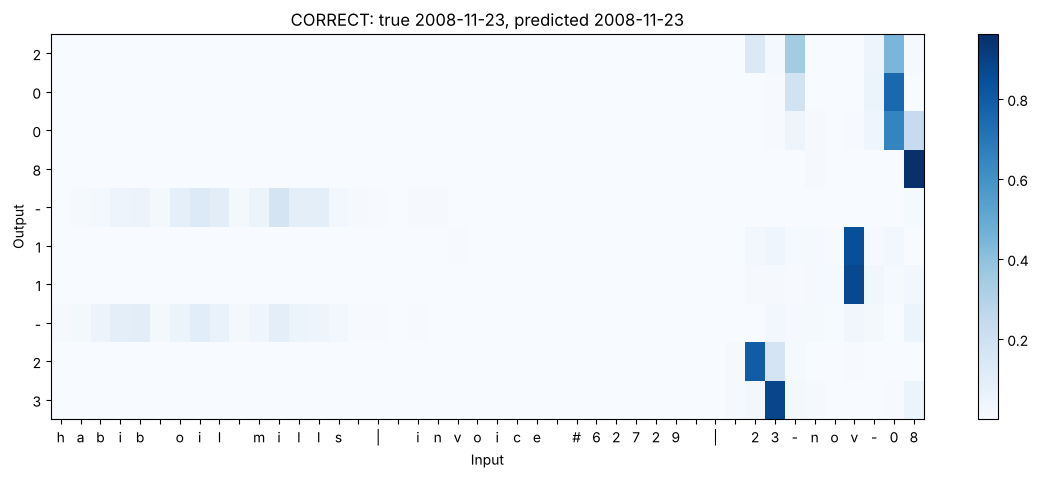

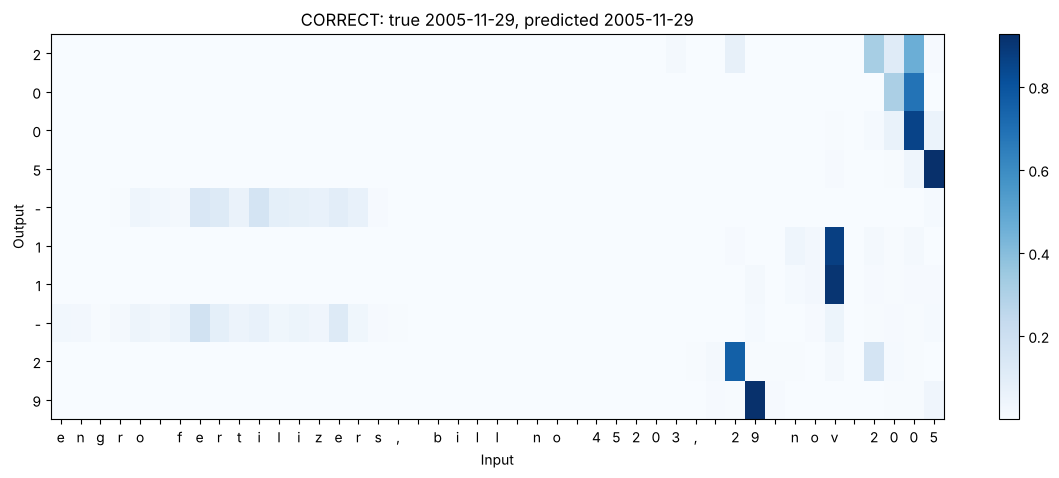

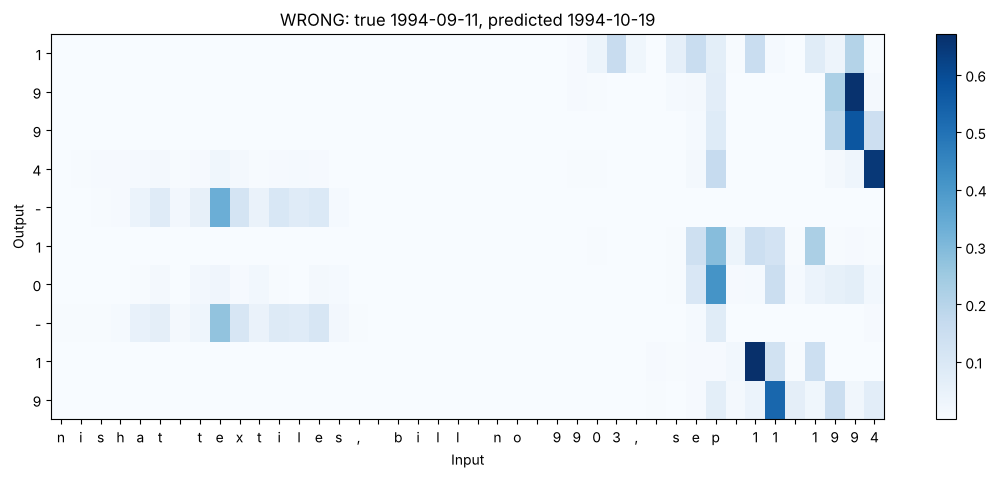

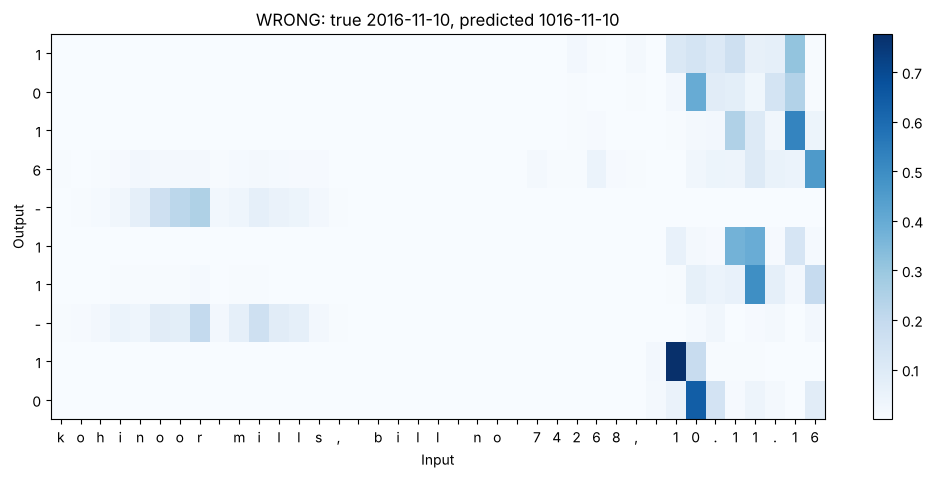

In [31]:
best_name = max(['Seq2Seq + Dot Attention', 'Seq2Seq + Additive Attention'],
                key=lambda n: np.mean(np.all(long_models[n]['pred'] == y_test, axis=1)))
best = long_models[best_name]
print('Best model:', best_name)

long_test = long_df.iloc[16000:].copy().reset_index(drop=True)
long_test['predicted'] = [to_text(p) for p in best['pred']]
long_test['base_predicted'] = [to_text(p) for p in long_models['Seq2Seq']['pred']]
long_test['correct'] = long_test['predicted'] == long_test['standard_date']
long_test['base_correct'] = long_test['base_predicted'] == long_test['standard_date']

correct_idx = np.where(long_test['correct'])[0][:2]
wrong_idx = np.where(~long_test['correct'])[0][:2]
print(long_test.loc[wrong_idx, ['invoice_text', 'standard_date', 'predicted']].to_string())

for i in list(correct_idx) + list(wrong_idx):
    status = 'CORRECT' if long_test['correct'].iloc[i] else 'WRONG'
    plot_attention(best['model'], best['score_model'], XL_test[i], long_test['invoice_text'].iloc[i], start_id, 10, inv_out,
                   title=f"{status}: true {long_test['standard_date'].iloc[i]}, predicted {long_test['predicted'].iloc[i]}")

In the correct examples the day, month and year digits look only at the date at the end of the string; the supplier name and the invoice number receive almost no weight from them, so the model has learned to locate the date inside the longer text. The only attention on the supplier name comes from the '-' separators in the output. In the first wrong example ('sep 11 1994', predicted 1994-10-19) the year is read correctly, but the attention for the month is split between 'sep' and the day digits, and the second day digit looks at the wrong '1', so both the month and the day come out wrong. In the second wrong example ('10.11.16', predicted 1016-11-10) the day and month are correct, but the year has only two digits, so the century is not in the input; the attention for the first year digit is spread over '.16' and the model wrote '1' instead of '2'. The heatmap shows exactly which output character went wrong and where the model looked, which is what an analyst needs to diagnose and fix the error.

### Task 5: Inputs that only the attention model got right

Long inputs wrong without attention but right with attention: 1408
                                                  invoice_text standard_date base_predicted   predicted
5   karachi steel works | invoice #57364 | sunday, 30 may 1993    1993-05-30     1993-05-03  1993-05-30
7                            packages ltd inv-71876 20/05/2024    2024-05-20     2024-05-02  2024-05-20
10                    zamzam foods, bill no 66093, 20 may 2025    2025-05-20     2025-05-02  2025-05-20
15       invoice 98048 from hashoo logistics dated sep 18 2006    2006-09-18     2006-08-19  2006-09-18
16               packages ltd, bill no 96122, january 07, 2006    2006-01-07     2006-07-01  2006-01-07
Short inputs wrong without attention but right with attention: 323
                invoice_date standard_date base_predicted attn_predicted
36               nov 30 2016    2016-11-30     2016-11-03     2016-11-30
38               09 aug 1993    1993-08-09     1993-09-06     1993-08-09
40   tuesday, 18 august

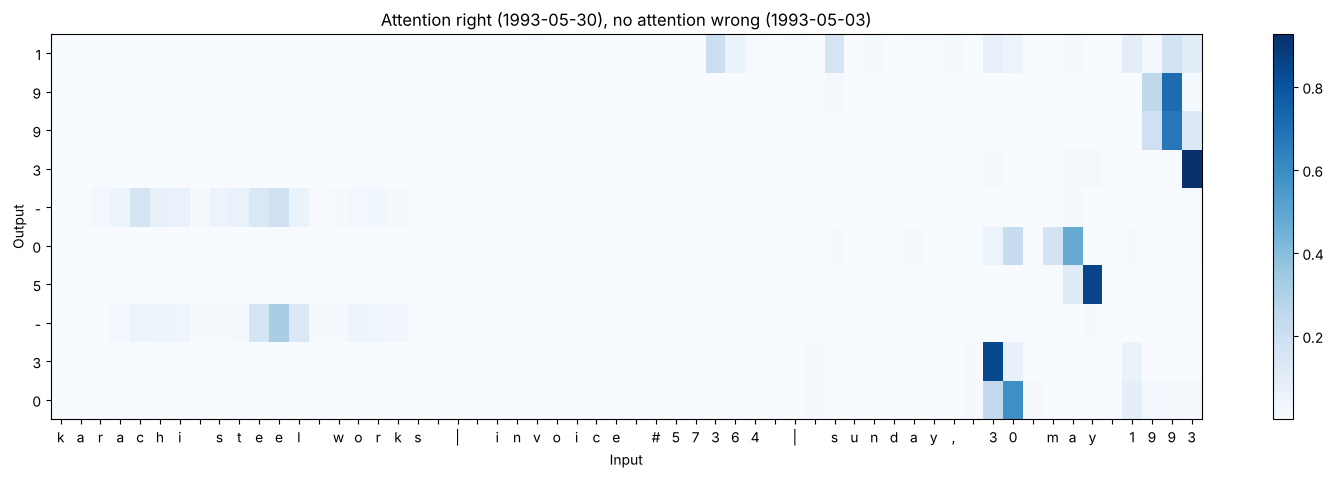

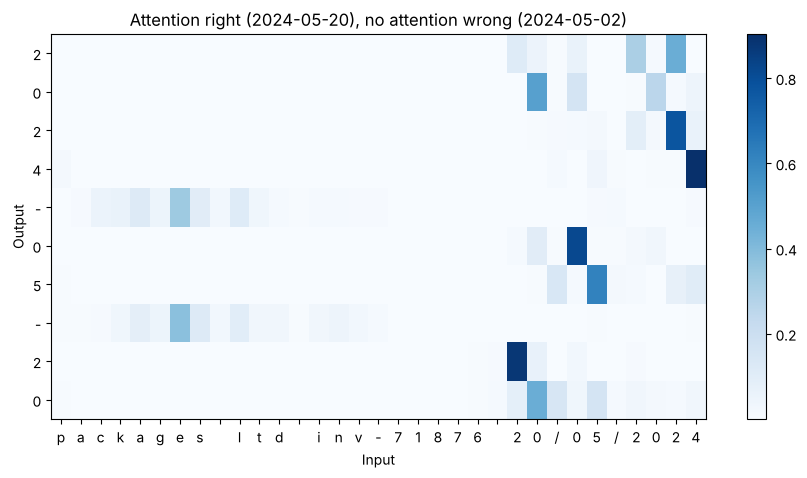

In [32]:
only_attn = long_test[(~long_test['base_correct']) & (long_test['correct'])]
print('Long inputs wrong without attention but right with attention:', len(only_attn))
print(only_attn[['invoice_text', 'standard_date', 'base_predicted', 'predicted']].head(5).to_string())

short_test = df.iloc[16000:].copy().reset_index(drop=True)
short_test['base_predicted'] = [to_text(p) for p in base_pred]
short_test['attn_predicted'] = [to_text(p) for p in attn_pred]
only_attn_short = short_test[(short_test['base_predicted'] != short_test['standard_date']) & (short_test['attn_predicted'] == short_test['standard_date'])]
print('Short inputs wrong without attention but right with attention:', len(only_attn_short))
print(only_attn_short.head(5).to_string())

for i in only_attn.index[:2]:
    plot_attention(best['model'], best['score_model'], XL_test[i], long_test['invoice_text'].iloc[i], start_id, 10, inv_out,
                   title=f"Attention right ({long_test['predicted'].iloc[i]}), no attention wrong ({long_test['base_predicted'].iloc[i]})")

Without attention 1,408 of the 4,000 long inputs were wrong but became right with attention, against 323 for the short inputs, so the benefit of attention grows a lot with longer input. In the examples the model without attention gets the year right but mixes up the day and month digits: '30 may' became 05-03, '20/05' became 05-02, 'january 07' became 07-01 and 'sep 18' became 08-19. Without attention the encoder must keep the date digits in its final state after reading the supplier name and invoice number as well, and the invoice-number digits overwrite part of that information. With attention the decoder looks directly at the exact characters of the day, month and year when it writes each of them, as the heatmaps show, so the text in front of the date does not get in the way.

### Task 6: Conclusion

The model to deploy is the seq2seq model with dot-product attention. On the plain invoice dates it reaches 1.0 exact-match accuracy, against 0.9193 without attention and 0.9625 with additive attention. When the date is hidden inside a longer string with a supplier name and an invoice number, the model without attention falls to 0.6478, because the whole string must pass through one fixed context vector of 64 numbers. The dot-product attention model keeps 0.9992 because it rebuilds the context at every output step from all encoder states and ignores the irrelevant parts of the text. Additive attention also drops, to 0.7612, so in this setting with 32 units and 20 epochs it did not learn to locate the date as well as dot-product attention.

Attention also helps beyond accuracy. The heatmaps show which characters were used for each output digit, so wrong predictions can be diagnosed and auditors can see why the system produced a particular date. The cost is small: only about 400 extra parameters and a modest increase in training time (169.7 s against 160.3 s on long inputs). Its limits are that it still fails on formats that never appeared in training, cannot recover a century that is missing from a two-digit year, and occasionally attends to the wrong digits, so outputs should be validated and uncertain cases reviewed by a person.

The same idea is the core of Transformer models such as BERT and GPT. A Transformer removes the LSTM completely and uses scaled dot-product attention between every pair of tokens (self-attention), with many attention heads working in parallel and stacked in layers. Each token builds its representation as a weighted average of all other tokens, exactly like the context vector in this lab. Because there is no step-by-step recurrence, Transformers can be trained in parallel on very large datasets, which is why they power modern translation systems, document-processing tools and chatbots.